<a href="https://colab.research.google.com/github/TheaHubner/RutgersGIS/blob/main/ps1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is my Colab. Work will be saved in Github and edited here. I can look at version history on Github and here under "File."

My project (unless I get access to my other dataset in reasonable time) will use a dataset I aqcuired from The Gun Violence Archive. This dataset contains all incidents of purposeful gun violence in America within the last 10 years. These incidents can be further divided into classifications (Purposeful Injury, Purposeful Death, Mass Shootings, Armed Robbery, and Domestic). I intend to explore the rates of these events in counties across America to identify counties with significantly high incident rates and to identify counties for which Domestic incidents are significantly different than the rates of all other types of violence.
I will continue to develop more specific research questions with Dr. Stansfield as we go.

Right now, my hypothesis is simply that rates of various types of gun violence rise parallel. I also hypothesis that counties with significantly higher rates of Domestic incidents will be rural counties.

In [ ]:
%%capture
!pip install mapclassify #sometimes have to install library which you get from https://pypi.org/

In [ ]:
import os, zipfile #basics
import pandas as pd #data management
import matplotlib.pyplot as plt #vis

import geopandas as gpd #gis/maps: a sister of pandas; does the job;
#tho not as fancy-interactive as folium or leafmap https://geopandas.org/

import mapclassify #need for thematic map classification

import seaborn as sns

#will display all output not just last command
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from google.colab.data_table import DataTable
DataTable.max_columns = 250

September 3 (Problem Set 0)

Here I added two shapefiles: One for states in the USA and one for counties. I would prefer to work with counties, if that is not too large a project to take on.


<Axes: >

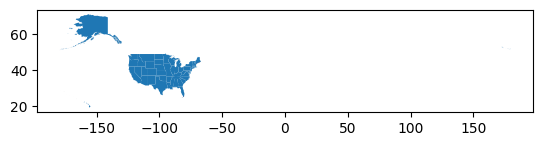

In [ ]:
#census shapefile with states in the USA
!wget -q -O us-states.zip https://www2.census.gov/geo/tiger/GENZ2018/shp/cb_2018_us_state_500k.zip

zip_ref = zipfile.ZipFile('us-states.zip', 'r'); zip_ref.extractall(); zip_ref.close() #just unzipping

shp_name = [f for f in os.listdir() if f.endswith('.shp')][0]
usC0 = gpd.read_file(shp_name) #load the shapefile with gpd as usC

territories = ['PR', 'GU', 'VI', 'AS', 'MP']
usC0_50 = usC0[~usC0['STUSPS'].isin(territories)]
usC0_50.plot()

<Axes: >

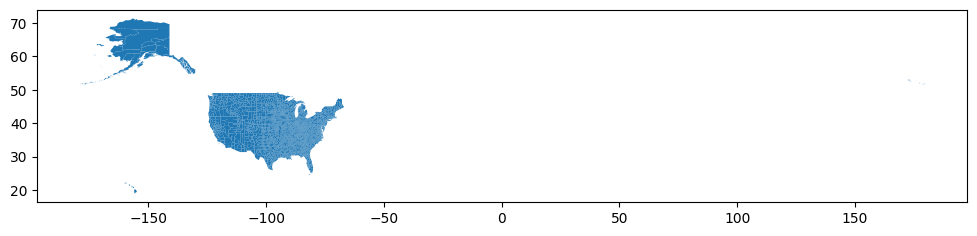

In [ ]:
#census shapefile with counties - using 5m version since 500k is currently being blocked
!wget -q -O us-counties.zip https://www2.census.gov/geo/tiger/GENZ2018/shp/cb_2018_us_county_5m.zip

zip_ref = zipfile.ZipFile('us-counties.zip', 'r'); zip_ref.extractall(); zip_ref.close() #just unzipping

shp_name_counties = [f for f in os.listdir() if f.endswith('.shp') and 'county' in f][0] #find the counties shapefile specifically
usCounties = gpd.read_file(shp_name_counties) #load the shapefile with gpd as usCounties

# counties don't have STUSPS, so filter territories using STATEFP instead
territory_fips = ['72', '66', '78', '60', '69']  # PR, GU, VI, AS, MP
usCounties_50 = usCounties[~usCounties['STATEFP'].isin(territory_fips)]
usCounties_50.plot(figsize=(12,8))

[sep10] Thematic Maps, color-coding polygons/lines/points

Help:
https://geographicdata.science/book/notebooks/05_choropleth.html

https://geopandas.org/en/stable/gallery/choropleths.html

https://geopandas.org/en/stable/gallery/choro_legends.html

## September 10: Join and Merge


1. Mount Drive
2. Import Pandas
3. Load my file (unfortunately the Excel takes a while but Box didn't work, not sure why)
4. Excel had 453394 rows (including headers). Check for match.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

In [ ]:
df = pd.read_excel('/content/drive/MyDrive/My Documents/Career Documents/Rutgers University/GIS/GVA Excel.xlsx', header=6)
print(df.shape)
df.columns.tolist()

(453387, 21)


['Incident ID',
 'Date',
 'State',
 'City',
 'Business or School',
 'Address',
 'Latitude',
 'Longitude',
 '# Victims Killed',
 '# Victims Injured',
 '# Suspect Killed',
 '# Suspects Injured',
 '# Suspects Unharmed',
 '# Suspects Arrested',
 'Accidental',
 'Mass Shooting',
 'Armed Robbery',
 'Domestic Violence',
 'Shot - Wounded/Injured',
 'Shot - Dead (murder, accidental, or suicide)',
 'Incident Characteristics']

The "Incident Characteristics" column delineates the incident type. However, incidents often have multiple tags (AKA fall into multiple categories), so I need to organize them before analysis.

The five categories I am comparing:
1. Domestic Violence
2. Armed Robbery
3. Mass Shootings
4. Willful Death
5. Willful Injury

For consistency, every incident will only belong to one category based on how the incident 'began.' A domestic violence incident will be labeled as such even if it becomes a mass shooting. Same for an armed robbery. The categories  bove are listed in order. The code below creates a new column that categorizes each incident.
To due formatting issues with the em dash in 'Shot - Wounded/Injured' and 'Shot - Dead...' I edited two new column names first.

In [ ]:
dead_col = [c for c in df.columns if 'Shot' in c and 'Dead' in c][0]
injured_col = [c for c in df.columns if 'Shot' in c and 'Wounded' in c][0]

print(dead_col)
print(injured_col)

Shot - Dead (murder, accidental, or suicide)
Shot - Wounded/Injured


In [ ]:
def classify_incident(row):
    if row['Domestic Violence'] == 'x':
        return 'Domestic Violence'
    elif row['Armed Robbery'] == 'x':
        return 'Armed Robbery'
    elif row['Mass Shooting'] == 'x':
        return 'Mass Shooting'
    elif row[dead_col] == 'x':
        return 'Willful Death'
    elif row[injured_col] == 'x':
        return 'Willful Injury'
    else:
        return None

df['Incident Type'] = df.apply(classify_incident, axis=1)

In [ ]:
#sanity check
df['Incident Type'].value_counts(dropna=False)

,count
Incident Type,
Willful Injury,249480
Willful Death,146954
Domestic Violence,28707
Armed Robbery,23159
Mass Shooting,5087


249480 + 146954 + 28707 + 231159 + 5087 = 453,387. It worked!

In [ ]:
# drop all of the unnecessary columns
df = df.drop(columns=[
    'Incident ID',
    'City',
    'Business or School',
    'Address',
    '# Victims Killed',
    '# Victims Injured',
    '# Suspect Killed',
    '# Suspects Injured',
    '# Suspects Unharmed',
    '# Suspects Arrested',
    'Accidental',
    'Mass Shooting',
    'Armed Robbery',
    'Domestic Violence',
    dead_col,
    injured_col,
])

print(df.shape)
df.columns.tolist()

(453387, 6)


['Date',
 'State',
 'Latitude',
 'Longitude',
 'Incident Characteristics',
 'Incident Type']

The next few cell blocks will use the latitude and longitude of each incident to match to the county FIPS codes.

In [ ]:
!pip install geopandas --quiet

In [ ]:
import geopandas as gpd
from shapely.geometry import Point

In [ ]:
# load the shapefile
!wget -q https://www2.census.gov/geo/tiger/TIGER2024/COUNTY/tl_2024_us_county.zip -O counties.zip
!unzip -q -o counties.zip -d counties
counties = gpd.read_file('counties/tl_2024_us_county.shp')
print(counties.shape)
counties.head()

(3235, 19)


,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,31,039,00835841,31039,0500000US31039,Cuming,Cuming County,06,H1,G4020,None,None,None,A,1477563042,10772508,+41.9158651,-096.7885168,"POLYGON ((-96.55525 41.82892, -96.55524 41.827..."
1,53,069,01513275,53069,0500000US53069,Wahkiakum,Wahkiakum County,06,H1,G4020,None,None,None,A,680980773,61564428,+46.2946377,-123.4244583,"POLYGON ((-123.72755 46.2645, -123.72756 46.26..."
2,35,011,00933054,35011,0500000US35011,De Baca,De Baca County,06,H1,G4020,None,None,None,A,6016818941,29090018,+34.3592729,-104.3686961,"POLYGON ((-104.89337 34.08894, -104.89337 34.0..."
3,31,109,00835876,31109,0500000US31109,Lancaster,Lancaster County,06,H1,G4020,339,30700,None,A,2169269508,22850511,+40.7835474,-096.6886584,"POLYGON ((-96.68493 40.5233, -96.69219 40.5231..."
4,31,129,00835886,31129,0500000US31129,Nuckolls,Nuckolls County,06,H1,G4020,None,None,None,A,1489645201,1718484,+40.1764918,-098.0468422,"POLYGON ((-98.2737 40.1184, -98.27374 40.1224,..."


In [ ]:
df[['Latitude', 'Longitude']].isna().sum()

,0
Latitude,61
Longitude,61


In [ ]:
df = df.dropna(subset=['Latitude', 'Longitude'])
print(df.shape)

(453326, 6)


In [ ]:
# Turn lat/long into point geometries
geometry = [Point(xy) for xy in zip(df['Longitude'], df['Latitude'])]
incidents_gdf = gpd.GeoDataFrame(df, geometry=geometry, crs='EPSG:4326')

# Make sure the shapefile uses the same coordinate system
counties = counties.to_crs('EPSG:4326')

# Spatial join: for each incident point, find which county polygon it falls inside
joined = gpd.sjoin(incidents_gdf, counties[['GEOID', 'NAME', 'geometry']], how='left', predicate='within')

print(joined.shape)
joined[['State', 'GEOID', 'NAME']].head(10)

(453326, 10)


,State,GEOID,NAME
0,Illinois,17031,Cook
1,Louisiana,22045,Iberia
2,Virginia,51800,Suffolk
3,Pennsylvania,42051,Fayette
4,Arkansas,05095,Monroe
5,North Carolina,37035,Catawba
6,Washington,53025,Grant
7,Illinois,17031,Cook
8,Georgia,13127,Glynn
9,Illinois,17031,Cook


In [ ]:
joined['GEOID'].isna().sum()

np.int64(0)

The next step is to compress! Rather than one incident per row, I want five rows for each county (one for each type of incident). I also want to include counties with 0 incidents of a kind in my map, so I will then merge with the shapefile again.

In [ ]:
county_counts = joined.groupby(['GEOID', 'NAME', 'Incident Type']).size().reset_index(name='Count')

county_wide = county_counts.pivot_table(
    index=['GEOID', 'NAME'],
    columns='Incident Type',
    values='Count',
    fill_value=0
).reset_index()

print(county_wide.shape)
county_wide.head(10)

(2982, 7)


Incident Type,GEOID,NAME,Armed Robbery,Domestic Violence,Mass Shooting,Willful Death,Willful Injury
0,01001,Autauga,3.0,12.0,1.0,20.0,25.0
1,01003,Baldwin,9.0,39.0,1.0,58.0,57.0
2,01005,Barbour,4.0,4.0,1.0,22.0,36.0
3,01007,Bibb,1.0,4.0,0.0,11.0,4.0
4,01009,Blount,0.0,11.0,1.0,12.0,10.0
5,01011,Bullock,0.0,0.0,2.0,16.0,11.0
6,01013,Butler,2.0,2.0,0.0,18.0,8.0
7,01015,Calhoun,3.0,30.0,2.0,88.0,65.0
8,01017,Chambers,5.0,6.0,3.0,25.0,34.0
9,01019,Cherokee,1.0,5.0,0.0,8.0,13.0


In [ ]:
# Start from the full county list, merge in your counts
final = counties[['GEOID', 'NAME']].merge(county_wide, on=['GEOID', 'NAME'], how='left')

# Any county with no incidents at all will have NaN in the 5 type columns — fill with 0
final = final.fillna(0)

print(final.shape)
final.head(10)

(3235, 7)


,GEOID,NAME,Armed Robbery,Domestic Violence,Mass Shooting,Willful Death,Willful Injury
0,31039,Cuming,0.0,1.0,0.0,0.0,2.0
1,53069,Wahkiakum,0.0,0.0,0.0,0.0,0.0
2,35011,De Baca,0.0,1.0,0.0,2.0,1.0
3,31109,Lancaster,17.0,14.0,2.0,55.0,129.0
4,31129,Nuckolls,0.0,1.0,0.0,1.0,0.0
5,72085,Las Piedras,0.0,0.0,0.0,0.0,0.0
6,46099,Minnehaha,5.0,12.0,2.0,39.0,100.0
7,48327,Menard,0.0,1.0,0.0,1.0,1.0
8,06091,Sierra,0.0,0.0,0.0,1.0,0.0
9,21053,Clinton,0.0,1.0,0.0,4.0,0.0


In [ ]:
final[['Armed Robbery', 'Domestic Violence', 'Mass Shooting', 'Willful Death', 'Willful Injury']].sum().sum()

np.float64(453326.0)

In [ ]:
final[final['NAME'] == 'Cook']

,GEOID,NAME,Armed Robbery,Domestic Violence,Mass Shooting,Willful Death,Willful Injury
250,13075,Cook,0.0,0.0,0.0,12.0,7.0
643,17031,Cook,1108.0,526.0,416.0,6568.0,23388.0
2002,27031,Cook,0.0,0.0,0.0,3.0,0.0


In [ ]:
final = final[final['GEOID'].str[:2] != '72']
print(final.shape)

(3157, 7)


In [ ]:
#reformat to remove decimal spaces
type_cols = ['Armed Robbery', 'Domestic Violence', 'Mass Shooting', 'Willful Death', 'Willful Injury']
final[type_cols] = final[type_cols].astype(int)
final.head()

,GEOID,NAME,Armed Robbery,Domestic Violence,Mass Shooting,Willful Death,Willful Injury
0,31039,Cuming,0,1,0,0,2
1,53069,Wahkiakum,0,0,0,0,0
2,35011,De Baca,0,1,0,2,1
3,31109,Lancaster,17,14,2,55,129
4,31129,Nuckolls,0,1,0,1,0


Now that spatial joining is complete, I will connect two additional pieces of data:
1. RUCC: The rural-Urban Continuum (also contains population data from 2020, halfway through the 10 years of data in this dataset, which can be fairly used to estimate per capita incident rates)
2. SAIPE: Small Area Income and Poverty Estimates (will drop extra rows and columns and state-level data)

In [ ]:
rucc = pd.read_excel('/content/drive/MyDrive/My Documents/Career Documents/Rutgers University/GIS/RUCC.xlsx')
print(rucc.shape)
rucc.head()

(3235, 6)


,FIPS,State,County_Name,Population_2020,RUCC_2023,Description
0,1001,AL,Autauga County,58805,2.0,"Metro - Counties in metro areas of 250,000 to ..."
1,1003,AL,Baldwin County,231767,3.0,Metro - Counties in metro areas of fewer than ...
2,1005,AL,Barbour County,25223,6.0,"Nonmetro - Urban population of 5,000 to 20,000..."
3,1007,AL,Bibb County,22293,1.0,Metro - Counties in metro areas of 1 million p...
4,1009,AL,Blount County,59134,1.0,Metro - Counties in metro areas of 1 million p...


In [ ]:
saipe = pd.read_excel('/content/drive/MyDrive/My Documents/Career Documents/Rutgers University/GIS/SAIPE.xls', header=3)
print(saipe.shape)
saipe.head(10)

(3196, 31)


,State FIPS Code,County FIPS Code,Postal Code,Name,"Poverty Estimate, All Ages",90% CI Lower Bound,90% CI Upper Bound,"Poverty Percent, All Ages",90% CI Lower Bound.1,90% CI Upper Bound.1,...,90% CI Upper Bound.5,Median Household Income,90% CI Lower Bound.6,90% CI Upper Bound.6,"Poverty Estimate, Age 0-4",90% CI Lower Bound.7,90% CI Upper Bound.7,"Poverty Percent, Age 0-4",90% CI Lower Bound.8,90% CI Upper Bound.8
0,0,0,US,United States,40354267,40105706,40602828,12.1,12,12.2,...,14.9,81604,81476,81732,2971742,2921307,3022177,16.5,16.2,16.8
1,1,0,AL,Alabama,763679,745419,781939,15.2,14.8,15.6,...,20.3,66704,65935,67473,64262,60186,68338,22.4,21,23.8
2,1,1,AL,Autauga County,7829,6646,9012,12.9,11,14.8,...,21.7,78840,71605,86075,.,.,.,.,.,.
3,1,3,AL,Baldwin County,26958,22767,31149,10.5,8.9,12.1,...,17.8,82519,77854,87184,.,.,.,.,.,.
4,1,5,AL,Barbour County,6093,4933,7253,28.1,22.7,33.5,...,50.6,45902,40508,51296,.,.,.,.,.,.
5,1,7,AL,Bibb County,4334,3531,5137,21.6,17.6,25.6,...,32.9,60359,53542,67176,.,.,.,.,.,.
6,1,9,AL,Blount County,6998,5667,8329,11.7,9.5,13.9,...,20.1,69371,64742,74000,.,.,.,.,.,.
7,1,11,AL,Bullock County,3026,2410,3642,36.7,29.2,44.2,...,52.4,36826,32465,41187,.,.,.,.,.,.
8,1,13,AL,Butler County,3650,2746,4554,20.3,15.3,25.3,...,41.3,47673,42388,52958,.,.,.,.,.,.
9,1,15,AL,Calhoun County,20451,17369,23533,18.5,15.7,21.3,...,30.1,53533,50678,56388,.,.,.,.,.,.


In [ ]:
saipe_counties = saipe[saipe['County FIPS Code'] != 0].copy()
print(saipe_counties.shape)

(3144, 31)


In [ ]:
saipe_counties.columns.tolist()

['State FIPS Code',
 'County FIPS Code',
 'Postal Code',
 'Name',
 'Poverty Estimate, All Ages',
 '90% CI Lower Bound',
 '90% CI Upper Bound',
 'Poverty Percent, All Ages',
 '90% CI Lower Bound.1',
 '90% CI Upper Bound.1',
 'Poverty Estimate, Age 0-17',
 '90% CI Lower Bound.2',
 '90% CI Upper Bound.2',
 'Poverty Percent, Age 0-17',
 '90% CI Lower Bound.3',
 '90% CI Upper Bound.3',
 'Poverty Estimate, Age 5-17 in Families',
 '90% CI Lower Bound.4',
 '90% CI Upper Bound.4',
 'Poverty Percent, Age 5-17 in Families',
 '90% CI Lower Bound.5',
 '90% CI Upper Bound.5',
 'Median Household Income',
 '90% CI Lower Bound.6',
 '90% CI Upper Bound.6',
 'Poverty Estimate, Age 0-4',
 '90% CI Lower Bound.7',
 '90% CI Upper Bound.7',
 'Poverty Percent, Age 0-4',
 '90% CI Lower Bound.8',
 '90% CI Upper Bound.8']

In [ ]:
saipe_clean = saipe_counties[['State FIPS Code', 'County FIPS Code', 'Postal Code', 'Name', 'Median Household Income', 'Poverty Percent, All Ages']].copy()
saipe_clean.head()

,State FIPS Code,County FIPS Code,Postal Code,Name,Median Household Income,"Poverty Percent, All Ages"
2,1,1,AL,Autauga County,78840,12.9
3,1,3,AL,Baldwin County,82519,10.5
4,1,5,AL,Barbour County,45902,28.1
5,1,7,AL,Bibb County,60359,21.6
6,1,9,AL,Blount County,69371,11.7


In [ ]:
#organize the FIPS codes for the merge
saipe_clean['FIPS'] = (
    saipe_clean['State FIPS Code'].astype(str).str.zfill(2) +
    saipe_clean['County FIPS Code'].astype(str).str.zfill(3)
)

saipe_clean[['State FIPS Code', 'County FIPS Code', 'FIPS']].head()

,State FIPS Code,County FIPS Code,FIPS
2,1,1,01001
3,1,3,01003
4,1,5,01005
5,1,7,01007
6,1,9,01009


In [ ]:
rucc['FIPS'] = rucc['FIPS'].astype(str).str.zfill(5)
rucc['FIPS'].head()

,FIPS
0,01001
1,01003
2,01005
3,01007
4,01009


In [ ]:
#merge!
master = final.rename(columns={'GEOID': 'FIPS'})
master = master.merge(rucc[['FIPS', 'Population_2020', 'RUCC_2023']], on='FIPS', how='left', indicator='rucc_merge')
master = master.merge(saipe_clean[['FIPS', 'Median Household Income']], on='FIPS', how='left', indicator='saipe_merge')

print(master.shape)
print(master['rucc_merge'].value_counts())
print(master['saipe_merge'].value_counts())
master.head()

(3157, 12)
rucc_merge
both          3157
left_only        0
right_only       0
Name: count, dtype: int64
saipe_merge
both          3144
left_only       13
right_only       0
Name: count, dtype: int64


,FIPS,NAME,Armed Robbery,Domestic Violence,Mass Shooting,Willful Death,Willful Injury,Population_2020,RUCC_2023,rucc_merge,Median Household Income,saipe_merge
0,31039,Cuming,0,1,0,0,2,9013,9.0,both,74666,both
1,53069,Wahkiakum,0,0,0,0,0,4422,8.0,both,77412,both
2,35011,De Baca,0,1,0,2,1,1698,9.0,both,48169,both
3,31109,Lancaster,17,14,2,55,129,322608,2.0,both,76062,both
4,31129,Nuckolls,0,1,0,1,0,4095,9.0,both,67032,both


In [ ]:
#let's catch the errors
missing_saipe = master[master['saipe_merge'] == 'left_only']
missing_saipe[['FIPS', 'NAME']]

#and then drop the territories
master = master[master['saipe_merge'] != 'left_only'].copy()
print(master.shape)

(3144, 12)


In [ ]:
master = master.drop(columns=['rucc_merge', 'saipe_merge'])
master.head()

,FIPS,NAME,Armed Robbery,Domestic Violence,Mass Shooting,Willful Death,Willful Injury,Population_2020,RUCC_2023,Median Household Income
0,31039,Cuming,0,1,0,0,2,9013,9.0,74666
1,53069,Wahkiakum,0,0,0,0,0,4422,8.0,77412
2,35011,De Baca,0,1,0,2,1,1698,9.0,48169
3,31109,Lancaster,17,14,2,55,129,322608,2.0,76062
4,31129,Nuckolls,0,1,0,1,0,4095,9.0,67032


In [ ]:
# create a new column for incidents per capita
type_cols = ['Armed Robbery', 'Domestic Violence', 'Mass Shooting', 'Willful Death', 'Willful Injury']

for col in type_cols:
    master[f'{col} per 100k'] = (master[col] / master['Population_2020']) * 100000

master.head()

,FIPS,NAME,Armed Robbery,Domestic Violence,Mass Shooting,Willful Death,Willful Injury,Population_2020,RUCC_2023,Median Household Income,Armed Robbery per 100k,Domestic Violence per 100k,Mass Shooting per 100k,Willful Death per 100k,Willful Injury per 100k
0,31039,Cuming,0,1,0,0,2,9013,9.0,74666,0.000000,11.095085,0.000000,0.000000,22.190170
1,53069,Wahkiakum,0,0,0,0,0,4422,8.0,77412,0.000000,0.000000,0.000000,0.000000,0.000000
2,35011,De Baca,0,1,0,2,1,1698,9.0,48169,0.000000,58.892815,0.000000,117.785630,58.892815
3,31109,Lancaster,17,14,2,55,129,322608,2.0,76062,5.269553,4.339632,0.619947,17.048554,39.986609
4,31129,Nuckolls,0,1,0,1,0,4095,9.0,67032,0.000000,24.420024,0.000000,24.420024,0.000000


In [ ]:
# create a total incidents column and a total incidents per capita column
master['Total Incidents'] = master[type_cols].sum(axis=1)
master['Total Incidents per 100k'] = (master['Total Incidents'] / master['Population_2020']) * 100000

master[['NAME', 'Total Incidents', 'Total Incidents per 100k']].head()

,NAME,Total Incidents,Total Incidents per 100k
0,Cuming,3,33.285255
1,Wahkiakum,0,0.000000
2,De Baca,4,235.571260
3,Lancaster,217,67.264296
4,Nuckolls,2,48.840049


In [ ]:
# saving the updated file as a CSV because running all of this code from scratch would be a pain
master.to_csv('/content/drive/MyDrive/My Documents/Career Documents/Rutgers University/GIS/master_county_data.csv', index=False)
print("Saved!")

Saved!


Making the maps:
Here, I begin a new session on Colab. I am using the file I saved last time so I don't need to run all of this from scratch.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install geopandas --quiet
import geopandas as gpd
import pandas as pd

In [ ]:
master = pd.read_csv('/content/drive/MyDrive/My Documents/Career Documents/Rutgers University/GIS/master_county_data.csv', dtype={'FIPS': str})
print(master.shape)
master.head()

(3144, 17)


,FIPS,NAME,Armed Robbery,Domestic Violence,Mass Shooting,Willful Death,Willful Injury,Population_2020,RUCC_2023,Median Household Income,Armed Robbery per 100k,Domestic Violence per 100k,Mass Shooting per 100k,Willful Death per 100k,Willful Injury per 100k,Total Incidents,Total Incidents per 100k
0,31039,Cuming,0,1,0,0,2,9013,9.0,74666,0.000000,11.095085,0.000000,0.000000,22.190170,3,33.285255
1,53069,Wahkiakum,0,0,0,0,0,4422,8.0,77412,0.000000,0.000000,0.000000,0.000000,0.000000,0,0.000000
2,35011,De Baca,0,1,0,2,1,1698,9.0,48169,0.000000,58.892815,0.000000,117.785630,58.892815,4,235.571260
3,31109,Lancaster,17,14,2,55,129,322608,2.0,76062,5.269553,4.339632,0.619947,17.048554,39.986609,217,67.264296
4,31129,Nuckolls,0,1,0,1,0,4095,9.0,67032,0.000000,24.420024,0.000000,24.420024,0.000000,2,48.840049


In [ ]:
!wget -q https://www2.census.gov/geo/tiger/TIGER2024/COUNTY/tl_2024_us_county.zip -O counties.zip
!unzip -q -o counties.zip -d counties
counties = gpd.read_file('counties/tl_2024_us_county.shp')
counties = counties.to_crs('EPSG:4326')
print(counties.shape)

(3235, 19)


I will create 7 maps. All will use the mapclassify install to identify the 'natural breaks' just like Prof. used.
1. Total Incident County per County
2. Total Incident Rate per Capita per County
3. Domestic Violence Count per County
4. Armed Robbery Count per County
5. Mass Shooting Count per County
6. Willful Death Count per County
7. Willful Injury Count per County

In [ ]:
!pip install mapclassify --quiet

import matplotlib.pyplot as plt

# Attach geometry, check the merge worked before plotting
map_gdf = counties[['GEOID', 'geometry']].merge(master, left_on='GEOID', right_on='FIPS', how='inner', indicator=True)
print(map_gdf['_merge'].value_counts())

zero_counties = map_gdf[map_gdf['Total Incidents'] == 0]
nonzero_counties = map_gdf[map_gdf['Total Incidents'] > 0]

_merge
both          3144
left_only        0
right_only       0
Name: count, dtype: int64


In [ ]:
# add thicker state lines to make the map more clear
states = counties.dissolve(by='STATEFP')

In [ ]:
#change the shades of blue because the light blue was toooooo light
import matplotlib.colors as mcolors
import numpy as np

blues_full = plt.cm.get_cmap('Blues')
blues_truncated = mcolors.LinearSegmentedColormap.from_list(
    'blues_truncated', blues_full(np.linspace(0.3, 1.0, 256))
)

/tmp/ipykernel_849/2326340199.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  blues_full = plt.cm.get_cmap('Blues')


/tmp/ipykernel_849/3867069229.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  top_geo['centroid'] = top_geo.geometry.centroid


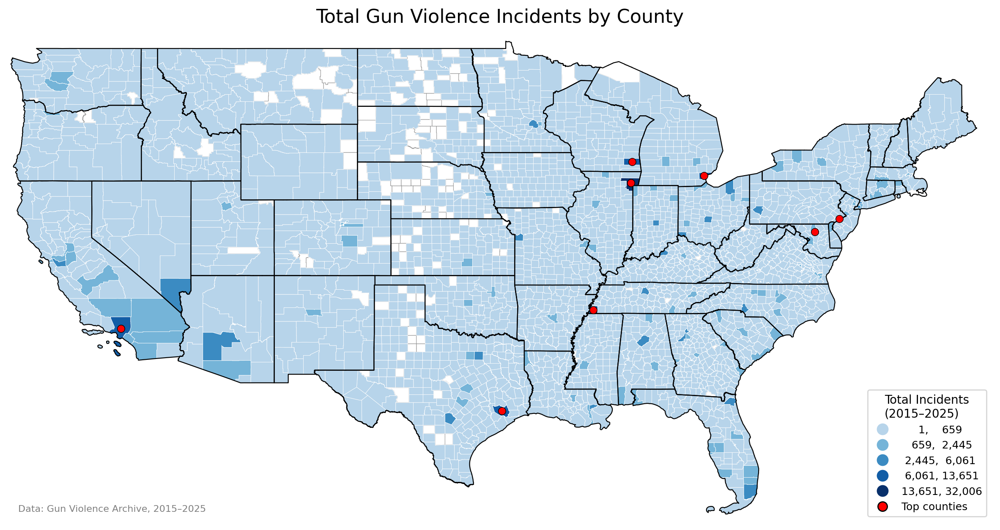

In [ ]:
#first map: Total incident rate per county, with zero-count counties in white
# and red dots placed over the few counties in the top 2 categories

top_geo = nonzero_counties[nonzero_counties['FIPS'].isin(top_counties['FIPS'])].copy()
top_geo['centroid'] = top_geo.geometry.centroid

fig, ax = plt.subplots(1, figsize=(15, 10), dpi=200)

zero_counties.plot(ax=ax, color='white', edgecolor='#999999', linewidth=0.4)
nonzero_counties.plot(
    ax=ax, column='Total Incidents', cmap=blues_truncated,
    scheme='natural_breaks', k=5,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'Total Incidents\n(2015–2025)', 'loc': 'lower right', 'fmt': '{:,.0f}'}
)

states.boundary.plot(ax=ax, color='black', linewidth=0.8)

ax.scatter(top_geo['centroid'].x, top_geo['centroid'].y, color='red', s=40, edgecolor='black', linewidth=0.5, zorder=5)

ax.text(0.01, 0.02, 'Data: Gun Violence Archive, 2015–2025', transform=ax.transAxes, fontsize=8, color='gray')

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_title('Total Gun Violence Incidents by County', fontsize=16)
ax.axis('off')

choropleth_legend = ax.get_legend()
handles = choropleth_legend.legend_handles
labels = [t.get_text() for t in choropleth_legend.get_texts()]
choropleth_legend.remove()

red_dot = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markeredgecolor='black', markersize=8)
handles.append(red_dot)
labels.append('Top counties')

ax.legend(handles=handles, labels=labels, title='Total Incidents\n(2015–2025)', loc='lower right', fontsize=9, frameon=True)

plt.show()

In [ ]:
#list of the counties in the darkest two categories that were given a red dot
import mapclassify

classifier = mapclassify.NaturalBreaks(nonzero_counties['Total Incidents'], k=5)
print(classifier.bins)  # shows the 5 breakpoints

threshold = classifier.bins[2]  # top of the 3rd bin = bottom edge of the top 2 bins
top_counties = nonzero_counties[nonzero_counties['Total Incidents'] > threshold][['FIPS', 'NAME', 'Total Incidents']].sort_values('Total Incidents', ascending=False)
top_counties

[  659.  2445.  6061. 13651. 32006.]


,FIPS,NAME,Total Incidents
624,17031,Cook,32006
579,42101,Philadelphia,13651
388,06037,Los Angeles,10481
1280,48201,Harris,9134
179,24510,Baltimore,8509
668,55079,Milwaukee,7461
279,26163,Wayne,6900
2169,47157,Shelby,6685


In [ ]:
#change the shades of green because the light green is tooooo light
greens_full = plt.cm.get_cmap('Greens')
greens_truncated = mcolors.LinearSegmentedColormap.from_list(
    'greens_truncated', greens_full(np.linspace(0.3, 1.0, 256))
)

/tmp/ipykernel_849/3905525743.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  greens_full = plt.cm.get_cmap('Greens')


In [ ]:
#list of counties in darkest two categories that will be given a red dot
classifier_pc = mapclassify.NaturalBreaks(nonzero_counties['Total Incidents per 100k'], k=5)
print(classifier_pc.bins)

threshold_pc = classifier_pc.bins[2]
top_counties_pc = nonzero_counties[nonzero_counties['Total Incidents per 100k'] > threshold_pc][['FIPS', 'NAME', 'Total Incidents per 100k']].sort_values('Total Incidents per 100k', ascending=False)
top_counties_pc

[  77.18120805  188.20833845  419.82387876  916.10069959 1704.03676661]


,FIPS,NAME,Total Incidents per 100k
3052,29510,St. Louis,1704.036767
2894,22071,Orleans,1578.397748
179,24510,Baltimore,1452.771688
2740,51730,Petersburg,1225.416941
1722,51740,Portsmouth,916.100700
650,51760,Richmond,910.815939
2872,28049,Hinds,910.240535
611,11001,District of Columbia,870.429051
579,42101,Philadelphia,851.167573
1806,22017,Caddo,822.373953


/tmp/ipykernel_849/3870453017.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  top_geo_pc['centroid'] = top_geo_pc.geometry.centroid


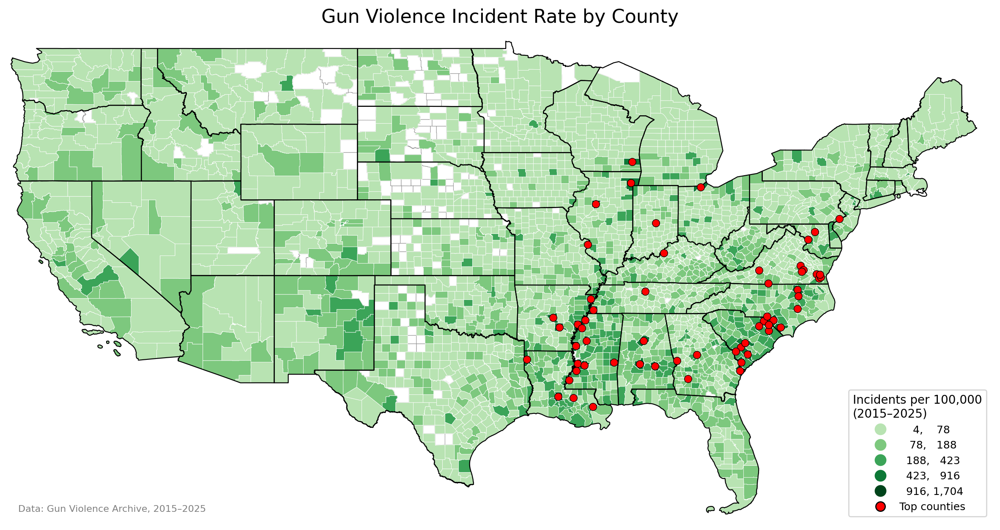

In [ ]:
#second map: total incident rate per county, with zero-count counties in white
# and a red dot for counties in the top 2 categories
top_geo_pc = nonzero_counties[nonzero_counties['FIPS'].isin(top_counties_pc['FIPS'])].copy()
top_geo_pc['centroid'] = top_geo_pc.geometry.centroid

fig, ax = plt.subplots(1, figsize=(15, 10), dpi=200)

zero_counties.plot(ax=ax, color='white', edgecolor='#999999', linewidth=0.4)
nonzero_counties.plot(
    ax=ax, column='Total Incidents per 100k', cmap=greens_truncated,
    scheme='natural_breaks', k=5,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'Incidents per 100,000\n(2015–2025)', 'loc': 'lower right', 'fmt': '{:,.0f}'}
)

states.boundary.plot(ax=ax, color='black', linewidth=0.8)

ax.scatter(top_geo_pc['centroid'].x, top_geo_pc['centroid'].y, color='red', s=40, edgecolor='black', linewidth=0.5, zorder=5)

ax.text(0.01, 0.02, 'Data: Gun Violence Archive, 2015–2025', transform=ax.transAxes, fontsize=8, color='gray')

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_title('Gun Violence Incident Rate by County', fontsize=16)
ax.axis('off')

choropleth_legend = ax.get_legend()
handles = choropleth_legend.legend_handles
labels = [t.get_text() for t in choropleth_legend.get_texts()]
choropleth_legend.remove()

red_dot = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markeredgecolor='black', markersize=8)
handles.append(red_dot)
labels.append('Top counties')

ax.legend(handles=handles, labels=labels, title='Incidents per 100,000\n(2015–2025)', loc='lower right', fontsize=9, frameon=True)

plt.show()

In [ ]:
#check that these aren't just tiny counties (AKA statistical noise)
nonzero_counties[nonzero_counties['Total Incidents per 100k'] > 900][['NAME', 'Total Incidents', 'Population_2020', 'Total Incidents per 100k']].sort_values('Total Incidents per 100k', ascending=False)

,NAME,Total Incidents,Population_2020,Total Incidents per 100k
3052,St. Louis,5139,301578,1704.036767
2894,Orleans,6061,383997,1578.397748
179,Baltimore,8509,585708,1452.771688
2740,Petersburg,410,33458,1225.416941
1722,Portsmouth,897,97915,916.100700
650,Richmond,2064,226610,910.815939
2872,Hinds,2073,227742,910.240535


In [ ]:
# the next few maps will separate the incident types.
#Accordingly, instead of using the natural breaks, we need to make them all match.

reds_full = plt.cm.get_cmap('Reds')
reds_truncated = mcolors.LinearSegmentedColormap.from_list(
    'reds_truncated', reds_full(np.linspace(0.3, 1.0, 256))
)

type_cols = ['Armed Robbery', 'Domestic Violence', 'Mass Shooting', 'Willful Death', 'Willful Injury']

all_type_values = pd.concat([
    nonzero_counties[nonzero_counties[col] > 0][col] for col in type_cols
])

shared_classifier = mapclassify.NaturalBreaks(all_type_values, k=5)
print(shared_classifier.bins)

[  378.  1458.  3817.  9634. 23388.]


/tmp/ipykernel_849/2009278845.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  reds_full = plt.cm.get_cmap('Reds')


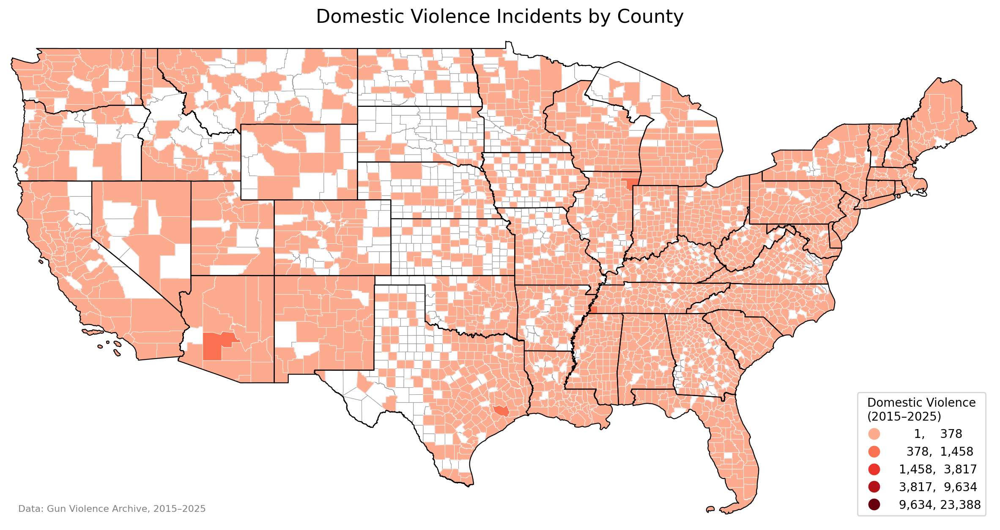

In [ ]:
#map 1: Domestic Violence

col = 'Domestic Violence'
zero_this = map_gdf[map_gdf[col] == 0]
nonzero_this = map_gdf[map_gdf[col] > 0]

fig, ax = plt.subplots(1, figsize=(15, 10), dpi=200)

zero_this.plot(ax=ax, color='white', edgecolor='#999999', linewidth=0.4)
nonzero_this.plot(
    ax=ax, column=col, cmap=reds_truncated,
    scheme='user_defined', classification_kwds={'bins': shared_classifier.bins},
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': f'{col}\n(2015–2025)', 'loc': 'lower right', 'fmt': '{:,.0f}'}
)

states.boundary.plot(ax=ax, color='black', linewidth=0.8)

ax.text(0.01, 0.02, 'Data: Gun Violence Archive, 2015–2025', transform=ax.transAxes, fontsize=8, color='gray')

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_title(f'{col} Incidents by County', fontsize=16)
ax.axis('off')

plt.show()

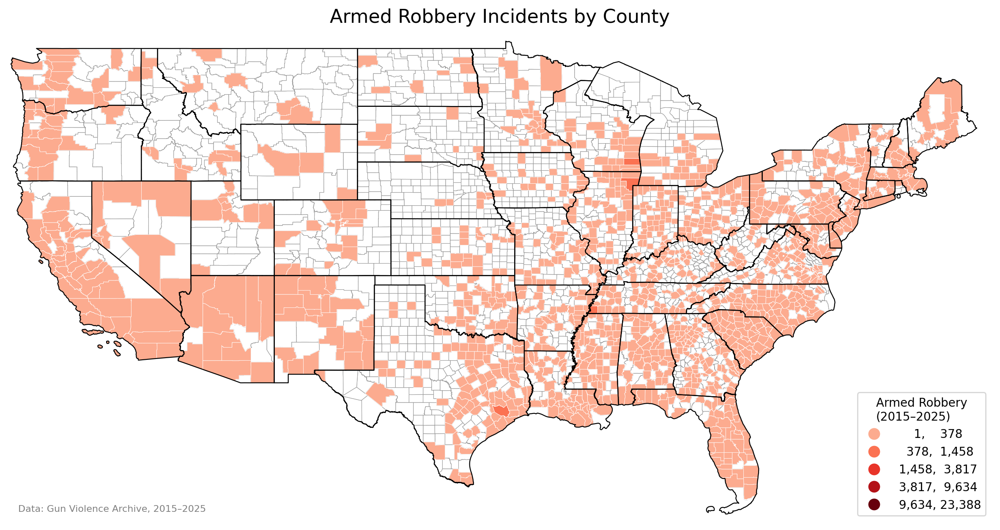

In [ ]:
#map 2: Armed Robbery
col = 'Armed Robbery'
zero_this = map_gdf[map_gdf[col] == 0]
nonzero_this = map_gdf[map_gdf[col] > 0]

fig, ax = plt.subplots(1, figsize=(15, 10), dpi=200)

zero_this.plot(ax=ax, color='white', edgecolor='#999999', linewidth=0.4)
nonzero_this.plot(
    ax=ax, column=col, cmap=reds_truncated,
    scheme='user_defined', classification_kwds={'bins': shared_classifier.bins},
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': f'{col}\n(2015–2025)', 'loc': 'lower right', 'fmt': '{:,.0f}'}
)

states.boundary.plot(ax=ax, color='black', linewidth=0.8)

ax.text(0.01, 0.02, 'Data: Gun Violence Archive, 2015–2025', transform=ax.transAxes, fontsize=8, color='gray')

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_title(f'{col} Incidents by County', fontsize=16)
ax.axis('off')

plt.show()

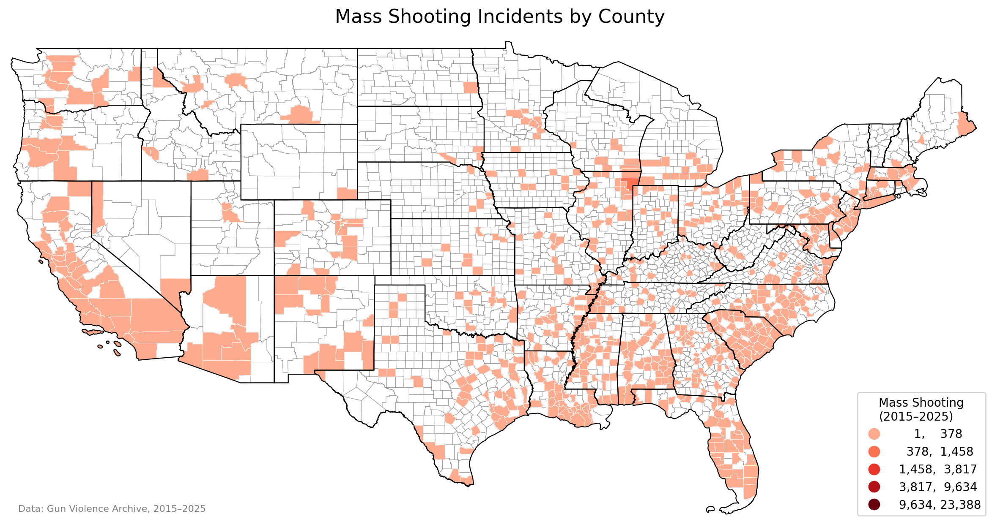

In [ ]:
#map 3: Mass Shootings
col = 'Mass Shooting'
zero_this = map_gdf[map_gdf[col] == 0]
nonzero_this = map_gdf[map_gdf[col] > 0]

fig, ax = plt.subplots(1, figsize=(15, 10), dpi=200)

zero_this.plot(ax=ax, color='white', edgecolor='#999999', linewidth=0.4)
nonzero_this.plot(
    ax=ax, column=col, cmap=reds_truncated,
    scheme='user_defined', classification_kwds={'bins': shared_classifier.bins},
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': f'{col}\n(2015–2025)', 'loc': 'lower right', 'fmt': '{:,.0f}'}
)

states.boundary.plot(ax=ax, color='black', linewidth=0.8)

ax.text(0.01, 0.02, 'Data: Gun Violence Archive, 2015–2025', transform=ax.transAxes, fontsize=8, color='gray')

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_title(f'{col} Incidents by County', fontsize=16)
ax.axis('off')

plt.show()

In [ ]:
#sanity check
master[master['Mass Shooting'] == master['Mass Shooting'].max()][['NAME', 'FIPS', 'Mass Shooting']]

,NAME,FIPS,Mass Shooting
624,Cook,17031,416


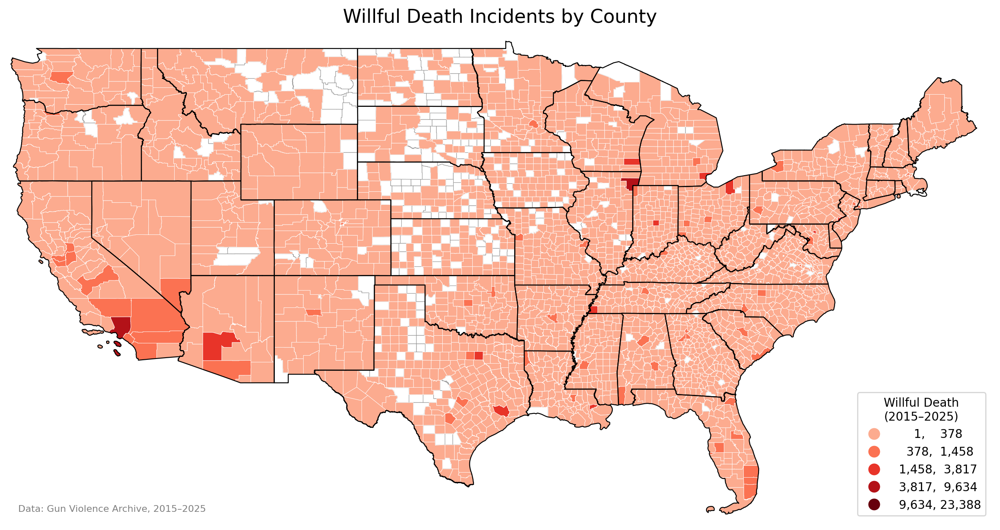

In [ ]:
col = 'Willful Death'
zero_this = map_gdf[map_gdf[col] == 0]
nonzero_this = map_gdf[map_gdf[col] > 0]

fig, ax = plt.subplots(1, figsize=(15, 10), dpi=200)

zero_this.plot(ax=ax, color='white', edgecolor='#999999', linewidth=0.4)
nonzero_this.plot(
    ax=ax, column=col, cmap=reds_truncated,
    scheme='user_defined', classification_kwds={'bins': shared_classifier.bins},
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': f'{col}\n(2015–2025)', 'loc': 'lower right', 'fmt': '{:,.0f}'}
)

states.boundary.plot(ax=ax, color='black', linewidth=0.8)

ax.text(0.01, 0.02, 'Data: Gun Violence Archive, 2015–2025', transform=ax.transAxes, fontsize=8, color='gray')

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_title(f'{col} Incidents by County', fontsize=16)
ax.axis('off')

plt.show()

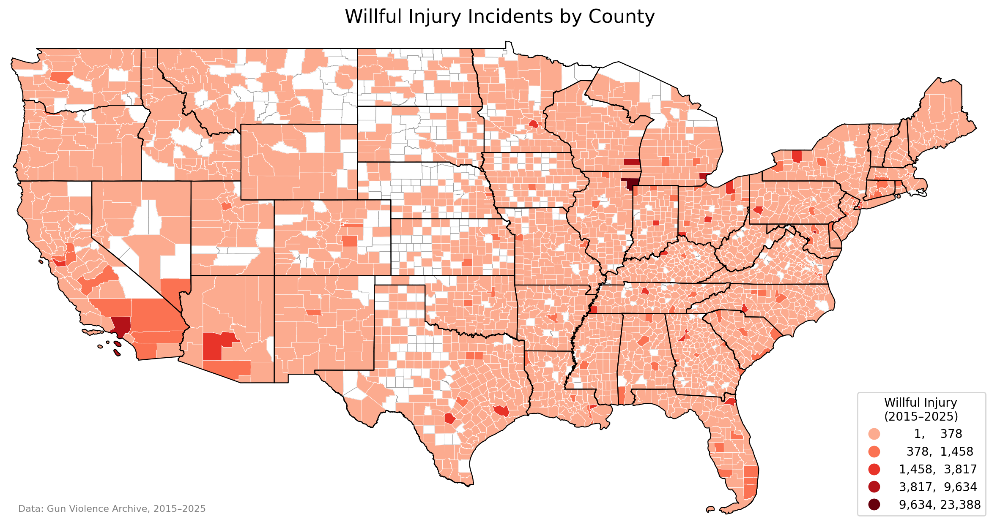

In [ ]:
col = 'Willful Injury'
zero_this = map_gdf[map_gdf[col] == 0]
nonzero_this = map_gdf[map_gdf[col] > 0]

fig, ax = plt.subplots(1, figsize=(15, 10), dpi=200)

zero_this.plot(ax=ax, color='white', edgecolor='#999999', linewidth=0.4)
nonzero_this.plot(
    ax=ax, column=col, cmap=reds_truncated,
    scheme='user_defined', classification_kwds={'bins': shared_classifier.bins},
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': f'{col}\n(2015–2025)', 'loc': 'lower right', 'fmt': '{:,.0f}'}
)

states.boundary.plot(ax=ax, color='black', linewidth=0.8)

ax.text(0.01, 0.02, 'Data: Gun Violence Archive, 2015–2025', transform=ax.transAxes, fontsize=8, color='gray')

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_title(f'{col} Incidents by County', fontsize=16)
ax.axis('off')

plt.show()

In [ ]:
#I took a break so I needed to rerun all of this but this can be skipped otherwise


from google.colab import drive
drive.mount('/content/drive')

!pip install geopandas mapclassify --quiet

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import mapclassify

# Reload your checkpoint
master = pd.read_csv('/content/drive/MyDrive/My Documents/Career Documents/Rutgers University/GIS/master_county_data.csv', dtype={'FIPS': str})

# Re-download shapefile
!wget -q https://www2.census.gov/geo/tiger/TIGER2024/COUNTY/tl_2024_us_county.zip -O counties.zip
!unzip -q -o counties.zip -d counties
counties = gpd.read_file('counties/tl_2024_us_county.shp')
counties = counties.to_crs('EPSG:4326')

# Rebuild geometry-attached table
map_gdf = counties[['GEOID', 'geometry']].merge(master, left_on='GEOID', right_on='FIPS', how='inner')

# Rebuild zero/nonzero split (based on Total Incidents, adjust per-map as needed)
zero_counties = map_gdf[map_gdf['Total Incidents'] == 0]
nonzero_counties = map_gdf[map_gdf['Total Incidents'] > 0]

# Rebuild state boundaries
states = counties.dissolve(by='STATEFP')

# Rebuild color ramps
blues_full = plt.cm.get_cmap('Blues')
blues_truncated = mcolors.LinearSegmentedColormap.from_list('blues_truncated', blues_full(np.linspace(0.3, 1.0, 256)))

greens_full = plt.cm.get_cmap('Greens')
greens_truncated = mcolors.LinearSegmentedColormap.from_list('greens_truncated', greens_full(np.linspace(0.3, 1.0, 256)))

reds_full = plt.cm.get_cmap('Reds')
reds_truncated = mcolors.LinearSegmentedColormap.from_list('reds_truncated', reds_full(np.linspace(0.3, 1.0, 256)))

# Rebuild shared classifier for the 5 type maps
type_cols = ['Armed Robbery', 'Domestic Violence', 'Mass Shooting', 'Willful Death', 'Willful Injury']
all_type_values = pd.concat([nonzero_counties[nonzero_counties[col] > 0][col] for col in type_cols])
shared_classifier = mapclassify.NaturalBreaks(all_type_values, k=5)

print("Setup complete:", master.shape, map_gdf.shape)

Mounted at /content/drive
Setup complete: (3144, 17) (3144, 19)


/tmp/ipykernel_7199/3144391438.py:36: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  blues_full = plt.cm.get_cmap('Blues')
/tmp/ipykernel_7199/3144391438.py:39: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  greens_full = plt.cm.get_cmap('Greens')
/tmp/ipykernel_7199/3144391438.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  reds_full = plt.cm.get_cmap('Reds')


In [ ]:
# the next thing I want to do is compare DV rates to other kinds to see if there
# are any counties in which DV rates are significantly higher
#the test below shows that counties that are statistically abnormal appear so
#only because the county only has 1 incident total, and it just happens to be DV
#and it's generally a tiny county anyway

master['DV Share of Total'] = (master['Domestic Violence'] / master['Total Incidents']) * 100
master[['NAME', 'Domestic Violence', 'Total Incidents', 'DV Share of Total']].sort_values('DV Share of Total', ascending=False).head(10)

,NAME,Domestic Violence,Total Incidents,DV Share of Total
3129,Cherry,1,1,100.0
3033,Gray,1,1,100.0
606,Carter,1,1,100.0
2974,Blanco,1,1,100.0
111,Boyd,1,1,100.0
1486,Bath,1,1,100.0
1388,Garfield,1,1,100.0
834,Liberty,1,1,100.0
2925,Sheridan,1,1,100.0
2806,Marshall,1,1,100.0


In [ ]:
#second test sets a minimum threshold of 20 DV events, so it filters out a lot of tiny counties
#this shows that now 1319 counties are included in the new search

min_threshold = 20
qualified = master[master['Total Incidents'] >= min_threshold].copy()
print(f"Counties meeting threshold: {qualified.shape[0]} out of {master.shape[0]}")

qualified[['NAME', 'Domestic Violence', 'Total Incidents', 'DV Share of Total']].sort_values('DV Share of Total', ascending=False).head(10)

Counties meeting threshold: 1319 out of 3144


,NAME,Domestic Violence,Total Incidents,DV Share of Total
1592,Whitley,16,39,41.025641
1169,Jackson,20,53,37.735849
2678,Iron,10,27,37.037037
1627,Washington,17,47,36.170213
2444,Sevier,19,53,35.849057
3038,Somerset,7,20,35.000000
2429,Franklin,7,20,35.000000
3122,Kent,7,20,35.000000
2435,Tishomingo,7,20,35.000000
558,Webster,8,23,34.782609


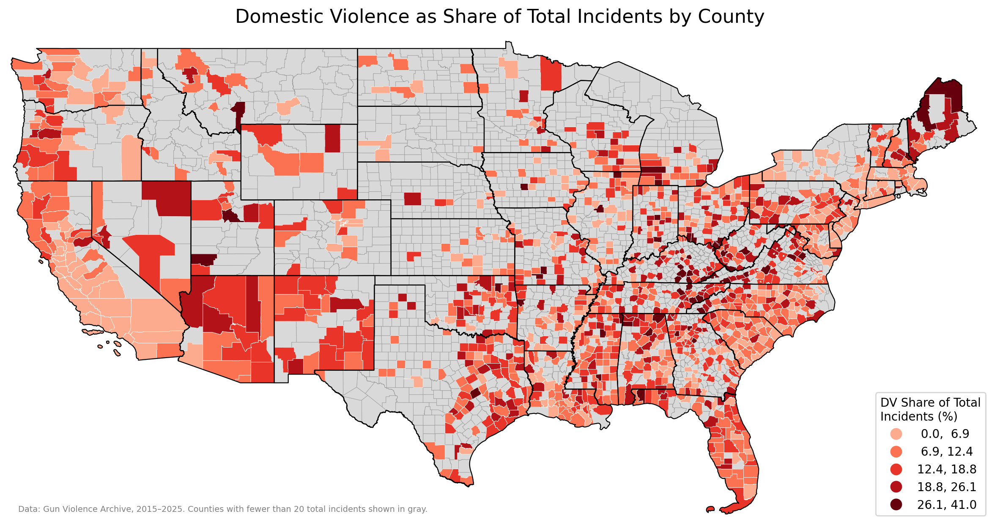

In [ ]:
#this map will highlight counties where DV rates are higher than other forms of gun violence
#both zero-count counties and counties with <20 DV incidents will be white

excluded = map_gdf[map_gdf['Total Incidents'] < min_threshold]
included = map_gdf[map_gdf['Total Incidents'] >= min_threshold].copy()
included['DV Share of Total'] = (included['Domestic Violence'] / included['Total Incidents']) * 100

fig, ax = plt.subplots(1, figsize=(15, 10), dpi=200)

excluded.plot(ax=ax, color='#d9d9d9', edgecolor='#999999', linewidth=0.3)
included.plot(
    ax=ax, column='DV Share of Total', cmap=reds_truncated,
    scheme='natural_breaks', k=5,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'DV Share of Total\nIncidents (%)', 'loc': 'lower right', 'fmt': '{:,.1f}'}
)

states.boundary.plot(ax=ax, color='black', linewidth=0.8)

ax.text(0.01, 0.02, f'Data: Gun Violence Archive, 2015–2025. Counties with fewer than {min_threshold} total incidents shown in gray.', transform=ax.transAxes, fontsize=7, color='gray')

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_title('Domestic Violence as Share of Total Incidents by County', fontsize=16)
ax.axis('off')

plt.show()

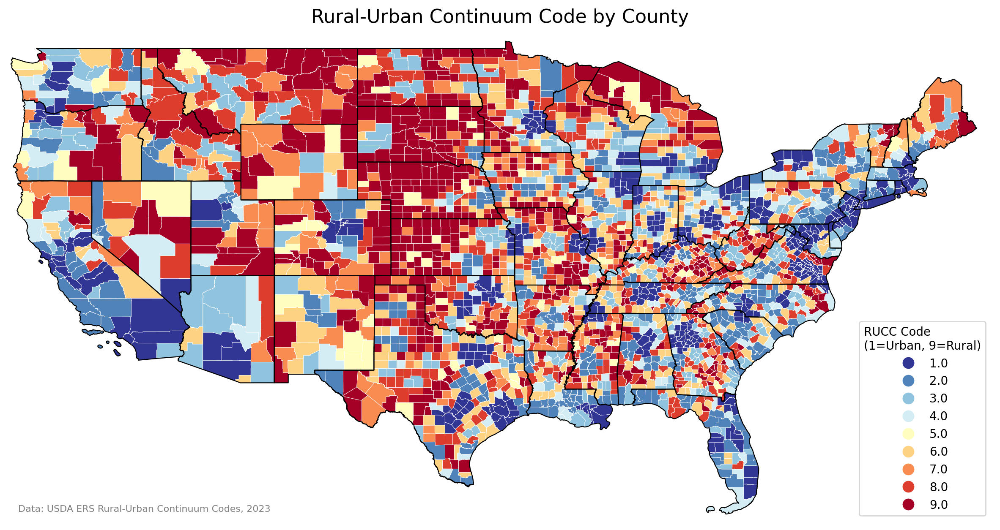

In [ ]:
#Now I am switching gears and mapping RUCC - rurality and urbanity
#results show no obvious relationship but the organization is different so
#the visual lack of connection doesn't mean anything just yet

fig, ax = plt.subplots(1, figsize=(15, 10), dpi=200)

map_gdf.plot(
    ax=ax, column='RUCC_2023', cmap='RdYlBu_r', categorical=True,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'RUCC Code\n(1=Urban, 9=Rural)', 'loc': 'lower right'}
)

states.boundary.plot(ax=ax, color='black', linewidth=0.8)

ax.text(0.01, 0.02, 'Data: USDA ERS Rural-Urban Continuum Codes, 2023', transform=ax.transAxes, fontsize=8, color='gray')

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_title('Rural-Urban Continuum Code by County', fontsize=16)
ax.axis('off')

plt.show()

In [ ]:
#prep SAIPE data for mapping

map_gdf['Median Household Income'] = pd.to_numeric(map_gdf['Median Household Income'], errors='coerce')
print(map_gdf['Median Household Income'].dtype)
print(map_gdf['Median Household Income'].isna().sum())

map_gdf[map_gdf['Median Household Income'].isna()][['NAME', 'FIPS']]

float64
1


,NAME,FIPS
2019,Kalawao,15005


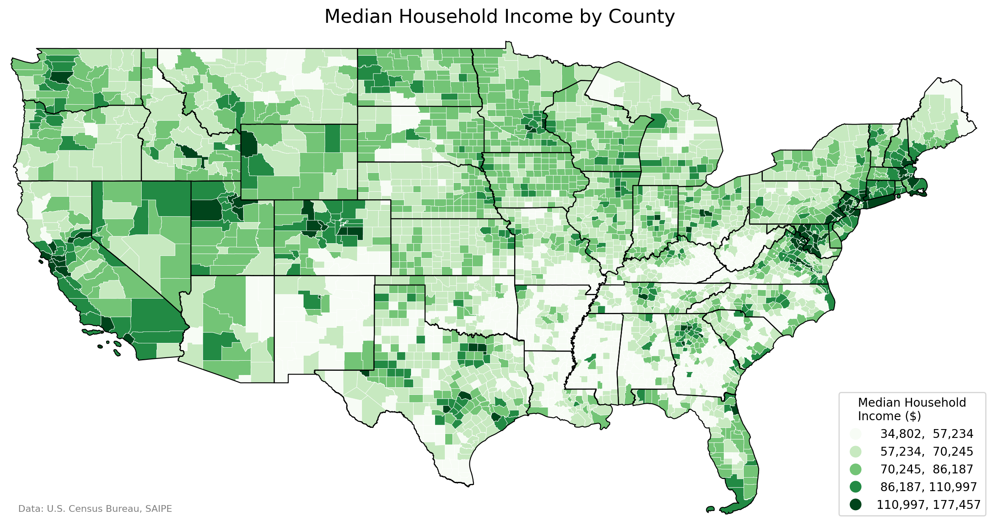

In [ ]:
#And here is the SAIPE map that measures county income by median
#this is from 2023, so we may want to switch to an earlier one
#since the GVA data is 2014-2025 ish and RUCC is 2020 (halfway point)

plt.close('all')

fig, ax = plt.subplots(1, figsize=(15, 10), dpi=200)

map_gdf.plot(
    ax=ax, column='Median Household Income', cmap='Greens',
    scheme='natural_breaks', k=5,
    legend=True, edgecolor='white', linewidth=0.3,
    legend_kwds={'title': 'Median Household\nIncome ($)', 'loc': 'lower right', 'fmt': '{:,.0f}'}
)

states.boundary.plot(ax=ax, color='black', linewidth=0.8)

ax.text(0.01, 0.02, 'Data: U.S. Census Bureau, SAIPE', transform=ax.transAxes, fontsize=8, color='gray')

ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_title('Median Household Income by County', fontsize=16)
ax.axis('off')

plt.show()

# notes to myself

### fa24

### 2023

TODO if anything go thru gpd again esp as more features being added!
<br>

the whole course, geo dat sci: [oct2023 not super urgent; skimmed thru it already]
https://darribas.org/gds_course/content/home.html

<br>oct2023 found 1 more; already incorporated most useful stuff , still  a useful reference:

old  version:
https://automating-gis-processes.github.io/CSC/index.html

new version:
https://autogis-site.readthedocs.io/en/latest/



<br>
LATER/MAYBE: [oct2023 but meh not clear advantage over gpd/folium]
 basemap! guess the first one! used to use it, but dead, depreciated in favor of cartopy
https://jakevdp.github.io/PythonDataScienceHandbook/04.13-geographic-data-with-basemap.html